In [1]:
import glob
import os

import numpy as np
import cv2
import matplotlib.pyplot as plt
import ultralytics
from tqdm import tqdm

import sys
sys.path.append("../../code/researches/objectdetectionmetrics/")
from metricsevaluator import MetricsEvaluator

In [2]:
tst_img_paths = sorted(glob.glob("datasets/position_db_pose/images/test/*.jpg"))
len(tst_img_paths)

490

In [3]:
model = ultralytics.YOLO("runs/positiondb_pose/weights/best.pt")

In [4]:
pytorch_total_params = sum(p.numel() for p in model.parameters())
pytorch_total_traineble_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(pytorch_total_params, pytorch_total_traineble_params)

2345793 0



image 1/1 /home/kyamkovyi/projects/pointgrab/gap9/ultralytics/datasets/position_db_pose/images/test/PG1_CIR_H300_Meeting_Room_02_11_35_35_2016-8_406.jpg: 480x640 8 persons, 82.7ms
Speed: 5.3ms preprocess, 82.7ms inference, 0.9ms postprocess per image at shape (1, 3, 480, 640)


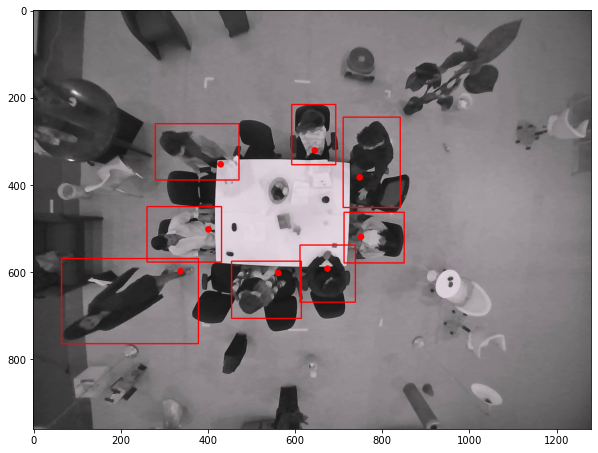

In [8]:
res = model.predict(tst_img_paths[1], conf=0.1)[0]

img = res.orig_img.copy()

for box in res.boxes.xyxy.numpy():
    cv2.rectangle(img, box[:2].astype(int), box[2:].astype(int), (255, 0, 0), 2)

for p in res.keypoints.xy.numpy():
    cv2.circle(img, p[0].astype(int), 4, (255, 0, 0), 5)

plt.figure(figsize=(10, 10))
plt.imshow(img);

In [5]:
tst_labels_pths = sorted(glob.glob("datasets/position_db_pose/labels/test/*.txt"))
len(tst_labels_pths)

490

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 490/490 [00:30<00:00, 16.14it/s]


P = 0.625. R = 0.981. F1 = 0.764. AP = 0.976


Text(0, 0.5, 'precision')

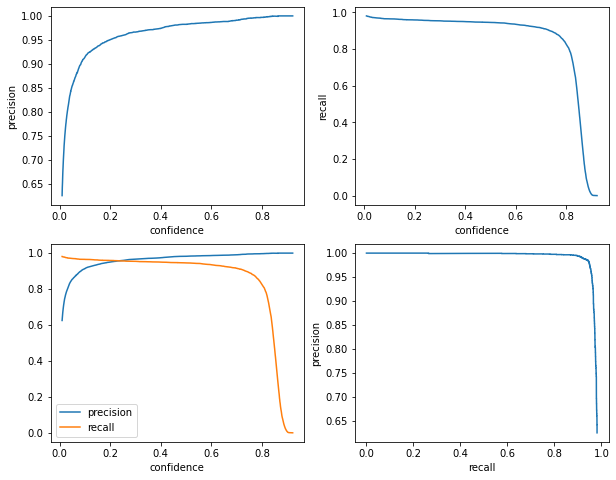

In [6]:
CONF_TH = 0.01

# init evaluator
evaluator = MetricsEvaluator(
    is_relative_coordinates=True,
    is_xywh_coordinates=True,
    img_size=(1280, 960)
)

for label_pth in tst_labels_pths:
    img_name = os.path.basename(label_pth).split(".")[0]

    with open(label_pth, "rt") as f:
        lines = f.readlines()
    
    for line in lines:
        _, x_c, y_c, w, h, x_p, y_p = [float(i) for i in line[:-1].split()] 
        x = x_c - w / 2
        y = y_c - h / 2
        
        evaluator.add_gt_box(
            img_path=img_name,
            class_name="person",
            bbox=[x_c, y_c, w, h]
        )

for img_pth in tqdm(tst_img_paths):
    img_name = os.path.basename(img_pth).split(".")[0]
    res = model.predict(img_pth, conf=CONF_TH, verbose=False)[0]
    for conf, box in zip(res.boxes.conf.numpy(), res.boxes.xywhn.numpy()):
        evaluator.add_det_box(
            img_path=img_name,
            class_name="person",
            bbox=box,
            confidence=conf
        )

result = evaluator.eval_conf_vals(0.5)[0]

precision = result["total TP"] / (result["total TP"] + result["total FP"])
recall = result["total TP"] / (result["total positives"])

f_score = 2 * precision * recall / (precision + recall)
print(f"P = {precision:.03f}. R = {recall:.03f}. F1 = {f_score:.03f}. AP = {result['AP']:.03f}")

plt.figure(figsize=(10, 8))
plt.subplot(2, 2, 1)
plt.plot(result["confidence"], result["precision"])
plt.xlabel("confidence")
plt.ylabel("precision")

plt.subplot(2, 2, 2)
plt.plot(result["confidence"], result["recall"])
plt.xlabel("confidence")
plt.ylabel("recall")

plt.subplot(2, 2, 3)
plt.plot(result["confidence"], result["precision"], label="precision")
plt.plot(result["confidence"], result["recall"], label="recall")
# plt.title("exp5")
# plt.vlines(0.11, 0, 1, label="0.11", colors="r")

plt.xlabel("confidence")
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(result["recall"], result["precision"])
plt.xlabel("recall")
plt.ylabel("precision")


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 490/490 [00:29<00:00, 16.70it/s]


P = 0.966. R = 0.954. F1 = 0.960. AP = 0.953


Text(0, 0.5, 'precision')

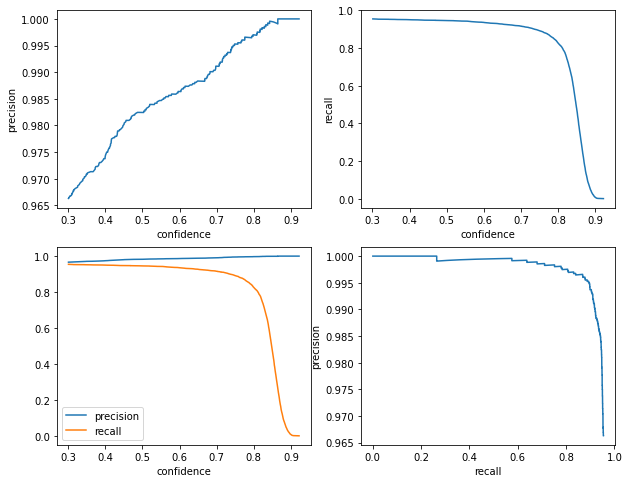

In [10]:
CONF_TH = 0.3

# init evaluator
evaluator = MetricsEvaluator(
    is_relative_coordinates=True,
    is_xywh_coordinates=True,
    img_size=(1280, 960)
)

for label_pth in tst_labels_pths:
    img_name = os.path.basename(label_pth).split(".")[0]

    with open(label_pth, "rt") as f:
        lines = f.readlines()
    
    for line in lines:
        _, x_c, y_c, w, h, x_p, y_p = [float(i) for i in line[:-1].split()] 
        x = x_c - w / 2
        y = y_c - h / 2
        
        evaluator.add_gt_box(
            img_path=img_name,
            class_name="person",
            bbox=[x_c, y_c, w, h]
        )

for img_pth in tqdm(tst_img_paths):
    img_name = os.path.basename(img_pth).split(".")[0]
    res = model.predict(img_pth, conf=CONF_TH, verbose=False)[0]
    for conf, box in zip(res.boxes.conf.numpy(), res.boxes.xywhn.numpy()):
        evaluator.add_det_box(
            img_path=img_name,
            class_name="person",
            bbox=box,
            confidence=conf
        )

result = evaluator.eval_conf_vals(0.5)[0]

precision = result["total TP"] / (result["total TP"] + result["total FP"])
recall = result["total TP"] / (result["total positives"])

f_score = 2 * precision * recall / (precision + recall)
print(f"P = {precision:.03f}. R = {recall:.03f}. F1 = {f_score:.03f}. AP = {result['AP']:.03f}")

plt.figure(figsize=(10, 8))
plt.subplot(2, 2, 1)
plt.plot(result["confidence"], result["precision"])
plt.xlabel("confidence")
plt.ylabel("precision")

plt.subplot(2, 2, 2)
plt.plot(result["confidence"], result["recall"])
plt.xlabel("confidence")
plt.ylabel("recall")

plt.subplot(2, 2, 3)
plt.plot(result["confidence"], result["precision"], label="precision")
plt.plot(result["confidence"], result["recall"], label="recall")
# plt.title("exp5")
# plt.vlines(0.11, 0, 1, label="0.11", colors="r")

plt.xlabel("confidence")
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(result["recall"], result["precision"])
plt.xlabel("recall")
plt.ylabel("precision")


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 490/490 [00:27<00:00, 17.56it/s]


P = 0.950. R = 0.947. F1 = 0.948. AP = 0.935


Text(0, 0.5, 'precision')

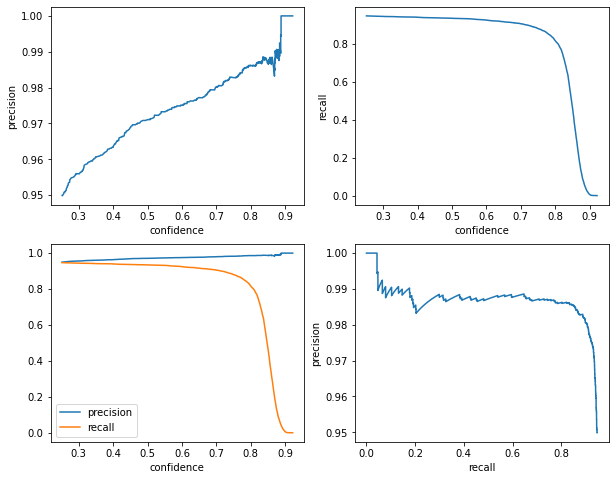

In [112]:
# positions

CONF_TH = 0.25
H = 0.05
W = 0.05 * 0.75

# init evaluator
evaluator = MetricsEvaluator(
    is_relative_coordinates=True,
    is_xywh_coordinates=True,
    img_size=(1280, 960)
)

for label_pth in tst_labels_pths:
    img_name = os.path.basename(label_pth).split(".")[0]

    with open(label_pth, "rt") as f:
        lines = f.readlines()
    
    for line in lines:
        _, x_c, y_c, w, h, x_p, y_p = [float(i) for i in line[:-1].split()] 
        x = x_c - w / 2
        y = y_c - h / 2
        
        evaluator.add_gt_box(
            img_path=img_name,
            class_name="person",
            bbox=[x_p - W // 2, y_p - H // 2, W, H]
        )
    # break

for img_pth in tqdm(tst_img_paths):
    img_name = os.path.basename(img_pth).split(".")[0]
    res = model.predict(img_pth, conf=CONF_TH, verbose=False)[0]
    for conf, p in zip(res.boxes.conf.numpy(), res.keypoints.xyn.numpy()):
        evaluator.add_det_box(
            img_path=img_name,
            class_name="person",
            bbox=[p[0][0] - W // 2, p[0][1] - H // 2, W, H],
            confidence=conf
        )
    # break

result = evaluator.eval_conf_vals(0.005)[0]

precision = result["total TP"] / (result["total TP"] + result["total FP"])
recall = result["total TP"] / (result["total positives"])

f_score = 2 * precision * recall / (precision + recall)
print(f"P = {precision:.03f}. R = {recall:.03f}. F1 = {f_score:.03f}. AP = {result['AP']:.03f}")

plt.figure(figsize=(10, 8))
plt.subplot(2, 2, 1)
plt.plot(result["confidence"], result["precision"])
plt.xlabel("confidence")
plt.ylabel("precision")

plt.subplot(2, 2, 2)
plt.plot(result["confidence"], result["recall"])
plt.xlabel("confidence")
plt.ylabel("recall")

plt.subplot(2, 2, 3)
plt.plot(result["confidence"], result["precision"], label="precision")
plt.plot(result["confidence"], result["recall"], label="recall")
# plt.title("exp5")
# plt.vlines(0.11, 0, 1, label="0.11", colors="r")

plt.xlabel("confidence")
plt.legend()

plt.subplot(2, 2, 4)
plt.plot(result["recall"], result["precision"])
plt.xlabel("recall")
plt.ylabel("precision")
